# Python Data Analytics Assignment 2: Data Visualization

**Topic:** Data cleaning and visualization using Pandas, Matplotlib, and Seaborn  
**Dataset:** Seaborn `taxis` dataset

## Objective
Load the taxis dataset, inspect and handle missing values, and create the visualizations specified in the assignment.

**Note:** Run the cells from top to bottom. The charts and summary values will be generated from the dataset in your environment.

## 1. Loading the Taxis Dataset
Load the dataset using Seaborn and inspect the first few rows.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = sns.load_dataset("taxis")

df.head()

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


In [ ]:
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())
print("\nDataset information:")
df.info()

Dataset shape: (6433, 14)

Column names:
['pickup', 'dropoff', 'passengers', 'distance', 'fare', 'tip', 'tolls', 'total', 'color', 'payment', 'pickup_zone', 'dropoff_zone', 'pickup_borough', 'dropoff_borough']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 6433 entries, 0 to 6432
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   pickup           6433 non-null   datetime64[us]
 1   dropoff          6433 non-null   datetime64[us]
 2   passengers       6433 non-null   int64         
 3   distance         6433 non-null   float64       
 4   fare             6433 non-null   float64       
 5   tip              6433 non-null   float64       
 6   tolls            6433 non-null   float64       
 7   total            6433 non-null   float64       
 8   color            6433 non-null   str           
 9   payment          6389 non-null   str           
 10  pickup_zone      6407 non-null 

## 2. Handling Missing Values
Check missing values in each column. Then fill numerical columns with their median and categorical columns with their mode. Finally, remove rows that still have missing values in important fields used for the analysis.

In [ ]:
missing_values = df.isnull().sum()
print("Missing values in each column:")
print(missing_values[missing_values > 0])

Missing values in each column:
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64


In [ ]:
df_clean = df.copy()

numerical_columns = df_clean.select_dtypes(include="number").columns
categorical_columns = df_clean.select_dtypes(include=["str", "object", "category", "bool"]).columns

for column in numerical_columns:
    df_clean[column] = df_clean[column].fillna(df_clean[column].median())

for column in categorical_columns:
    if df_clean[column].isnull().any() and not df_clean[column].mode().empty:
        df_clean[column] = df_clean[column].fillna(df_clean[column].mode()[0])

df_clean["pickup"] = pd.to_datetime(df_clean["pickup"], errors="coerce")

critical_columns = ["pickup", "fare", "pickup_borough", "payment", "distance", "tip", "total"]
df_clean = df_clean.dropna(subset=critical_columns)

print("Rows before cleaning:", len(df))
print("Rows after cleaning:", len(df_clean))
print("\nMissing values after cleaning:")
print(df_clean.isnull().sum()[df_clean.isnull().sum() > 0])

Rows before cleaning: 6433
Rows after cleaning: 6433

Missing values after cleaning:
Series([], dtype: int64)


**Interpretation:** The missing-value summary identifies columns that need attention. Numerical values are imputed with the median, which is less sensitive to extreme values than the mean. Categorical values are filled with the most frequent category. Rows missing critical fields for the required plots are removed. The code also converts `pickup` to datetime format.

## 3. Visualizations Using Matplotlib / Pandas Plot

### 3.1 Line Chart — Fare Over Time
The pickup timestamp is on the x-axis and fare is on the y-axis. The data is sorted by pickup time for a clear line chart.

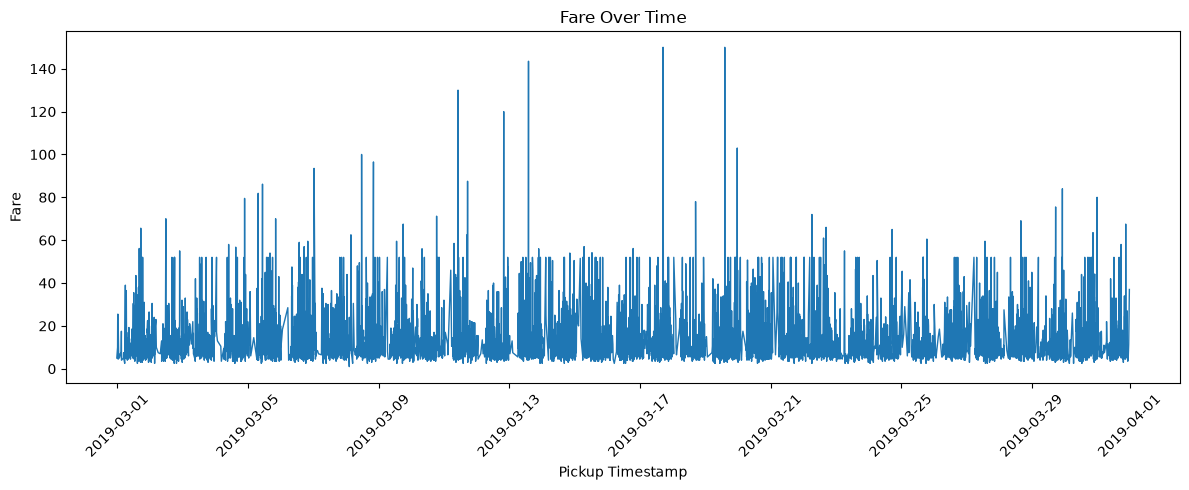

In [6]:
line_data = df_clean[["pickup", "fare"]].sort_values("pickup")

plt.figure(figsize=(12, 5))
plt.plot(line_data["pickup"], line_data["fare"], linewidth=1)
plt.title("Fare Over Time")
plt.xlabel("Pickup Timestamp")
plt.ylabel("Fare")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 3.2 Bar Chart — Total Fare by Pickup Borough
Group the data by `pickup_borough` and calculate the sum of fares.

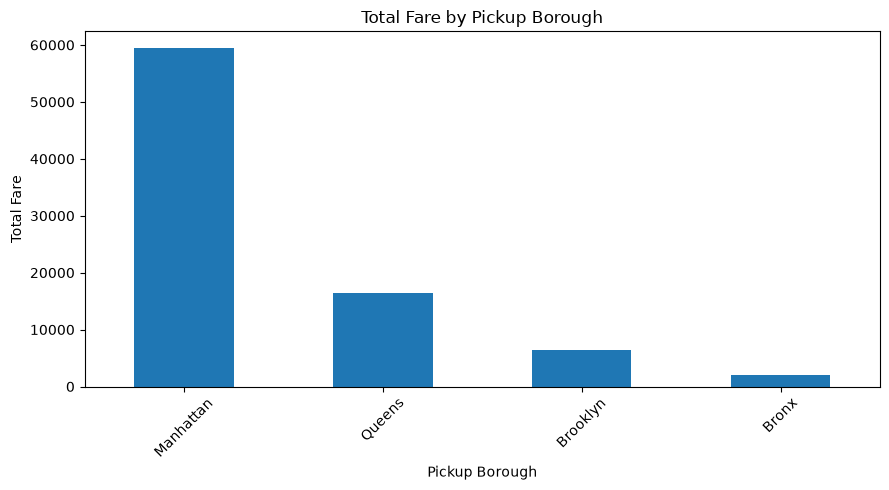

pickup_borough
Manhattan    59426.42
Queens       16382.06
Brooklyn      6327.48
Bronx         2078.91
Name: fare, dtype: float64


In [7]:
borough_fare = df_clean.groupby("pickup_borough", observed=False)["fare"].sum().sort_values(ascending=False)

borough_fare.plot(kind="bar", figsize=(9, 5))
plt.title("Total Fare by Pickup Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Total Fare")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print(borough_fare)

### 3.3 Pie Chart — Trips by Payment Method
Each slice represents the number of trips for a payment method.

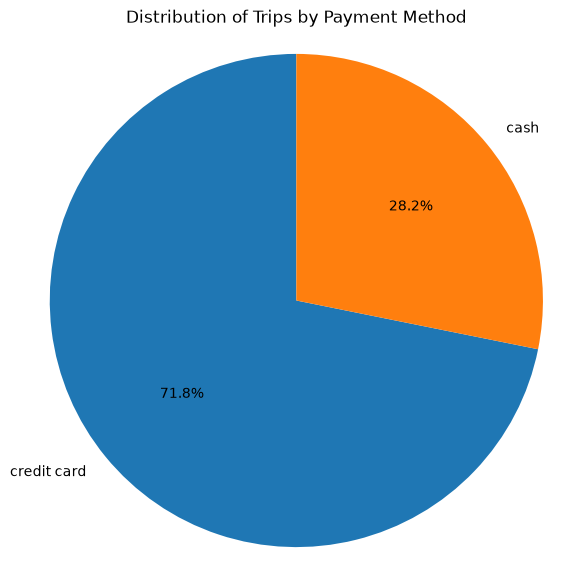

In [8]:
payment_counts = df_clean["payment"].value_counts()

plt.figure(figsize=(7, 7))
plt.pie(payment_counts, labels=payment_counts.index, autopct="%1.1f%%", startangle=90)
plt.title("Distribution of Trips by Payment Method")
plt.axis("equal")
plt.show()

### 3.4 Histogram — Distribution of Distance
Use 30 bins to show the distribution of trip distances.

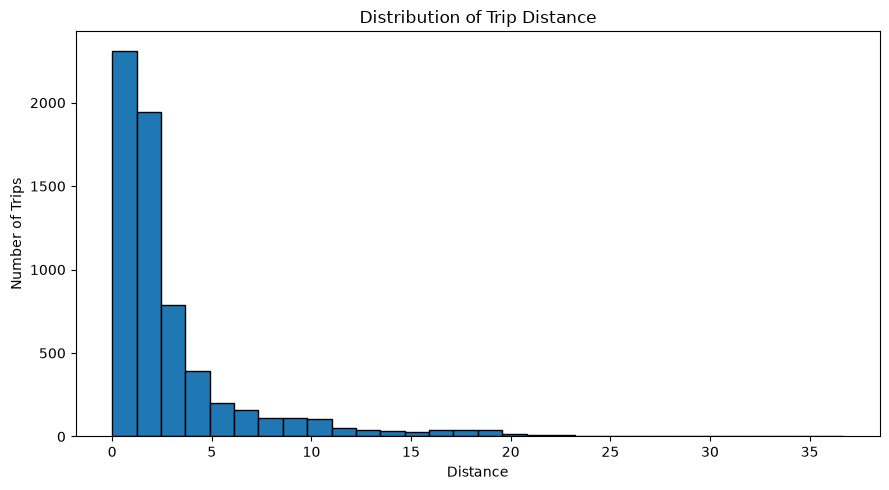

In [9]:
plt.figure(figsize=(9, 5))
plt.hist(df_clean["distance"], bins=30, edgecolor="black")
plt.title("Distribution of Trip Distance")
plt.xlabel("Distance")
plt.ylabel("Number of Trips")
plt.tight_layout()
plt.show()

### 3.5 Box Plot — Tip by Pickup Borough
The box plot compares the distribution of tip amounts across pickup boroughs.

<Figure size 1000x500 with 0 Axes>

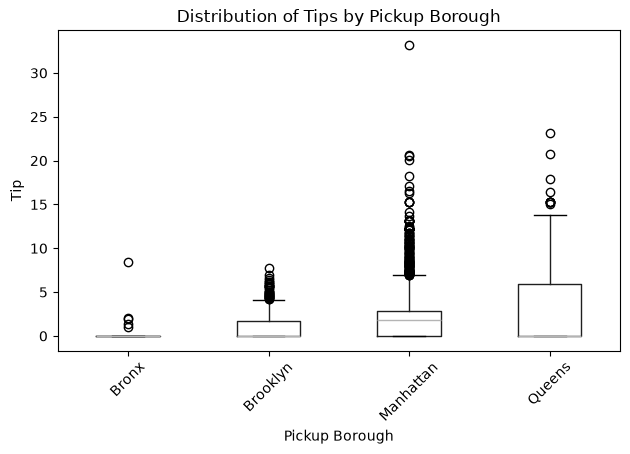

In [10]:
plt.figure(figsize=(10, 5))
df_clean.boxplot(column="tip", by="pickup_borough", grid=False)
plt.title("Distribution of Tips by Pickup Borough")
plt.suptitle("")
plt.xlabel("Pickup Borough")
plt.ylabel("Tip")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 4. Visualizations Using Seaborn

### 4.1 Count Plot — Number of Trips by Pickup Borough

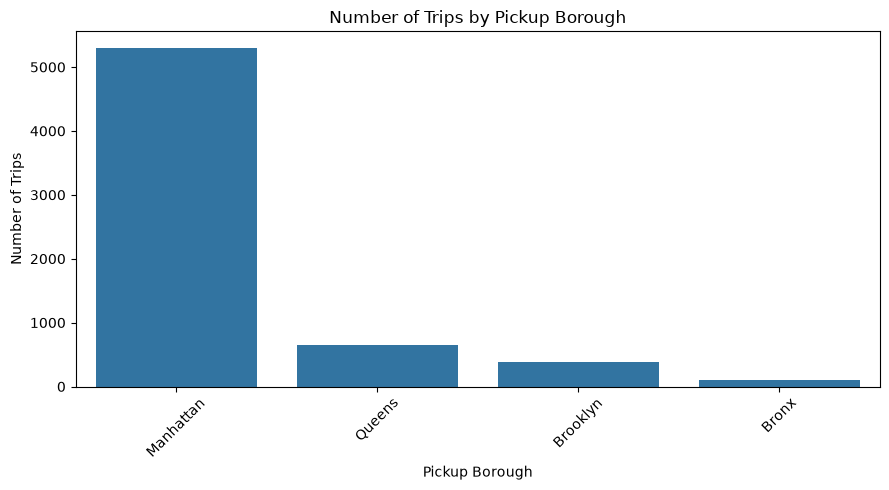

In [11]:
plt.figure(figsize=(9, 5))
sns.countplot(data=df_clean, x="pickup_borough", order=df_clean["pickup_borough"].value_counts().index)
plt.title("Number of Trips by Pickup Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Number of Trips")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 4.2 Scatter Plot — Distance vs Fare
Points are colored by pickup borough to compare the relationship between distance and fare.

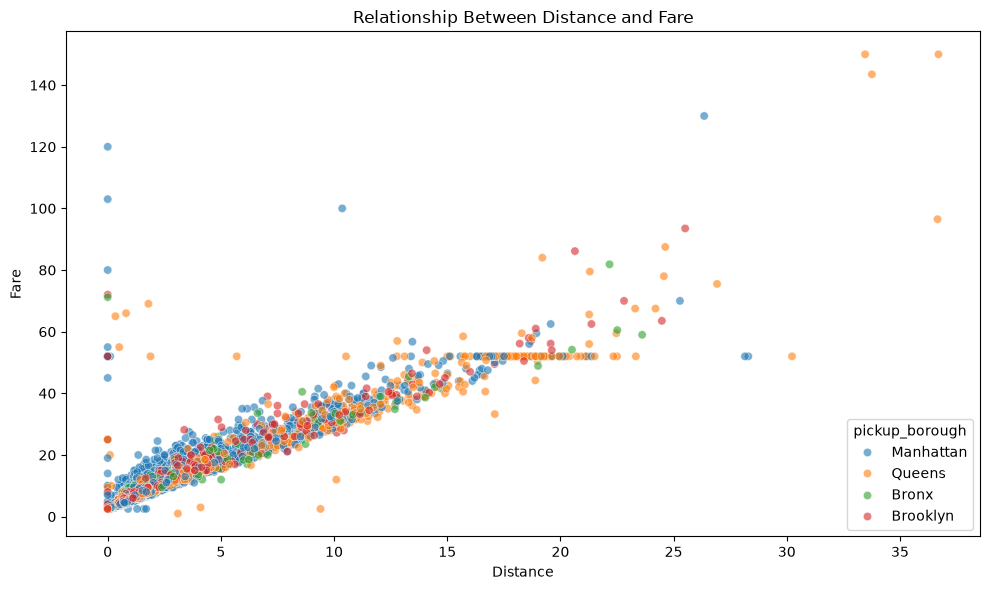

In [12]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_clean, x="distance", y="fare", hue="pickup_borough", alpha=0.6)
plt.title("Relationship Between Distance and Fare")
plt.xlabel("Distance")
plt.ylabel("Fare")
plt.tight_layout()
plt.show()

### 4.3 Heatmap — Correlation Between Numerical Variables
Calculate the correlation matrix for distance, fare, tip, tolls, and total.

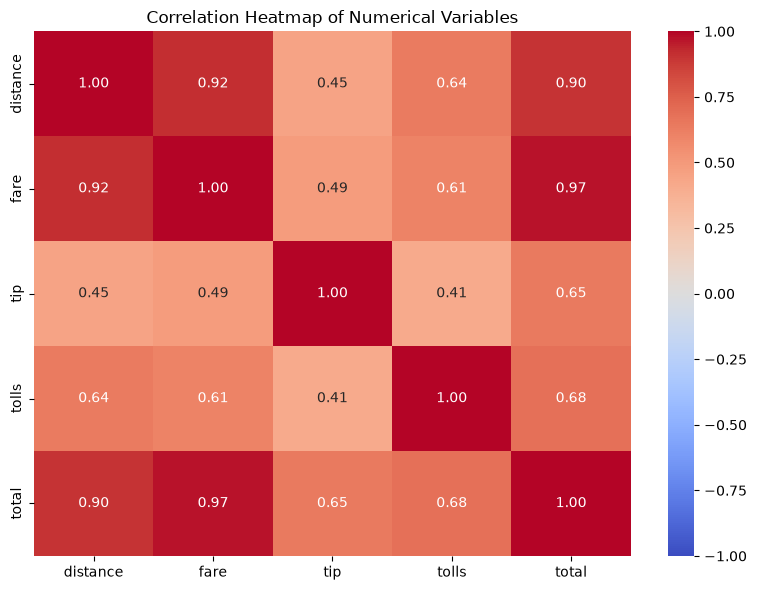

In [13]:
correlation_columns = ["distance", "fare", "tip", "tolls", "total"]
correlation_matrix = df_clean[correlation_columns].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlation Heatmap of Numerical Variables")
plt.tight_layout()
plt.show()

### 4.4 Pair Plot — Pairwise Relationships
Use `pickup_zone` as the hue to compare the numerical variables across zones. To keep the plot readable and efficient, a sample of up to 1,000 rows is used.

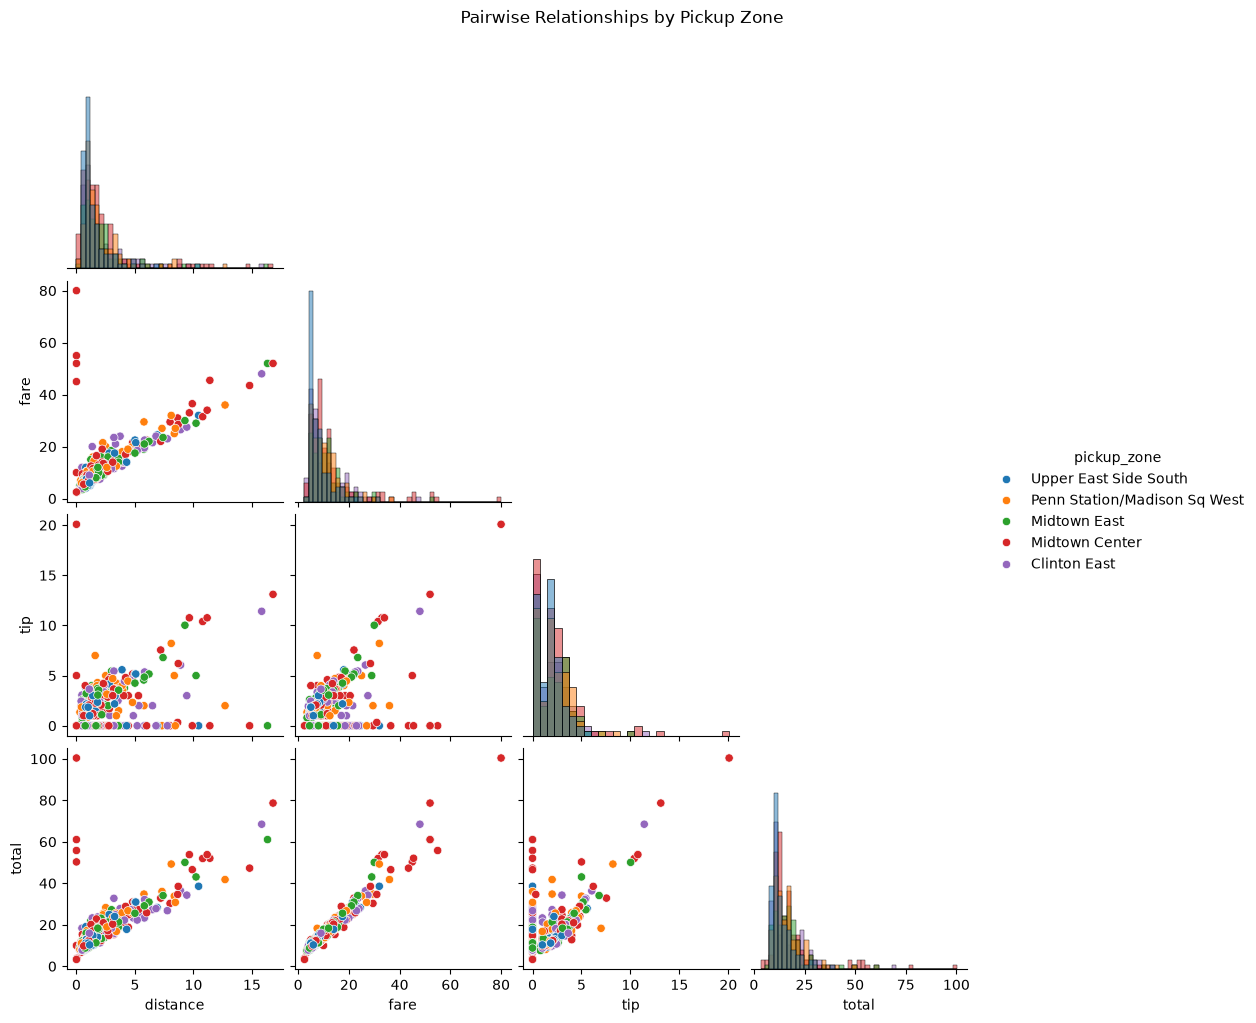

In [14]:
pair_columns = ["distance", "fare", "tip", "total", "pickup_zone"]
pair_data = df_clean[pair_columns].dropna().copy()

top_zones = pair_data["pickup_zone"].value_counts().head(5).index
pair_data = pair_data[pair_data["pickup_zone"].isin(top_zones)]

if len(pair_data) > 500:
    pair_data = pair_data.sample(n=500, random_state=42)

if not pair_data.empty:
    pair_plot = sns.pairplot(
        data=pair_data,
        vars=["distance", "fare", "tip", "total"],
        hue="pickup_zone",
        diag_kind="hist",
        corner=True,
        height=2.5
    )
    pair_plot.fig.suptitle("Pairwise Relationships by Pickup Zone", y=1.02)
    plt.show()
else:
    print("No valid data is available for the pair plot.")

### 4.5 Violin Plot — Fare by Payment Method
The violin plot shows the distribution and density of fares for each payment method.

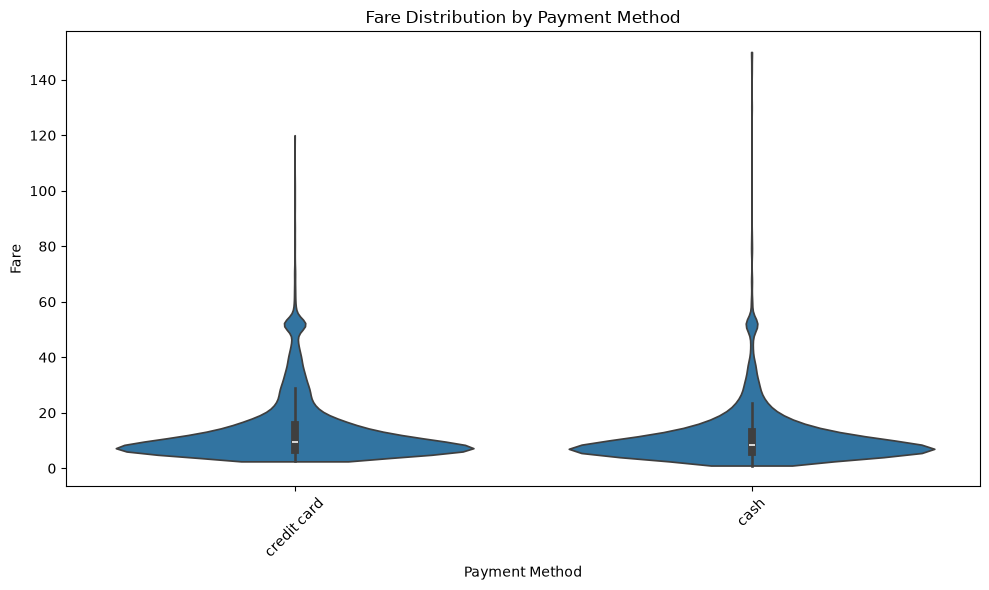

In [15]:
violin_data = df_clean[["payment", "fare"]].dropna().copy()

violin_data["payment"] = violin_data["payment"].astype(str)

if not violin_data.empty:
    plt.figure(figsize=(10, 6))

    sns.violinplot(
        data=violin_data,
        x="payment",
        y="fare",
        cut=0
    )

    plt.title("Fare Distribution by Payment Method")
    plt.xlabel("Payment Method")
    plt.ylabel("Fare")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
else:
    print("No valid data is available for the violin plot.")